In [15]:
import pandas as pd

### Loading the MovieLens Dataset

The MovieLens dataset consists of multiple CSV files. Pansas is used to load each CSV file into a DF for exploration and preprocessing

In [17]:
movies = pd.read_csv('../data/raw/movies.csv')
ratings = pd.read_csv('../data/raw/ratings.csv')
tags = pd.read_csv('../data/raw/tags.csv')
links = pd.read_csv('../data/raw/links.csv')

### Data Exploration / Data Quality Check: Below is the chronological process order for each dataframe

- Display the first 10 rows of each dataframe
- Find shape of each dataframe
- Gather information about each dataframe 
- Check for missing values
- Check for duplicates
- Check for unique values in each column
- Check for correlations between columns
- Visualize the data using plots and charts

In [19]:
movies.head(10)

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
5,6,Heat (1995),Action|Crime|Thriller
6,7,Sabrina (1995),Comedy|Romance
7,8,Tom and Huck (1995),Adventure|Children
8,9,Sudden Death (1995),Action
9,10,GoldenEye (1995),Action|Adventure|Thriller


In [22]:
print(movies.shape)

(9742, 3)


In [23]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB


In [24]:
movies.isnull().sum()

movieId    0
title      0
genres     0
dtype: int64

In [25]:
movies.duplicated().sum()

np.int64(0)

In [ ]:
movies['movieId'].is_unique

True

In [43]:
movies['title'].is_unique
movies[movies["title"].duplicated(keep=False)].sort_values("title")

,movieId,title,genres
4169,6003,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Thriller
9106,144606,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Romance|Thriller
650,838,Emma (1996),Comedy|Drama|Romance
5601,26958,Emma (1996),Romance
5854,32600,Eros (2004),Drama
9135,147002,Eros (2004),Drama|Romance
2141,2851,Saturn 3 (1980),Adventure|Sci-Fi|Thriller
9468,168358,Saturn 3 (1980),Sci-Fi|Thriller
5931,34048,War of the Worlds (2005),Action|Adventure|Sci-Fi|Thriller
6932,64997,War of the Worlds (2005),Action|Sci-Fi


### Title Uniqueness

The title column was examined for uniqueness. Several movie titles appeared more than once despite having different movieId values. Some duplicate titles also contained different genre classifications. Therefore, movieId will be used as the unique identifier for movies rather than the title.

In [ ]:
## WHich genres/genre combinations occur most frequently in the dataset?
movies["genres"].value_counts()

genres
Drama                                     1053
Comedy                                     946
Comedy|Drama                               435
Comedy|Romance                             363
Drama|Romance                              349
                                          ... 
Adventure|Mystery|Sci-Fi|Thriller            1
Action|Comedy|Crime|Horror                   1
Action|Adventure|Children|Sci-Fi             1
Action|Adventure|Comedy|Fantasy|Sci-Fi       1
Action|Animation|Comedy|Fantasy              1
Name: count, Length: 951, dtype: int64

In [9]:
ratings.head(10)

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931
5,1,70,3.0,964982400
6,1,101,5.0,964980868
7,1,110,4.0,964982176
8,1,151,5.0,964984041
9,1,157,5.0,964984100


In [26]:
print (ratings.shape)

(100836, 4)


In [27]:
ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


In [30]:
ratings.isnull().sum()

userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

In [31]:
ratings.duplicated().sum()

np.int64(0)

In [ ]:
## Unique users in the dataset

ratings['userId'].nunique()

610

In [48]:
## Unique movies in the dataset

ratings['movieId'].nunique()

9724

In [50]:
ratings['rating'].value_counts()

rating
4.0    26818
3.0    20047
5.0    13211
3.5    13136
4.5     8551
2.0     7551
2.5     5550
1.0     2811
1.5     1791
0.5     1370
Name: count, dtype: int64

In [51]:
ratings['rating'].describe()

count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

In [10]:
tags.head(10)

,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200
5,2,89774,Tom Hardy,1445715205
6,2,106782,drugs,1445715054
7,2,106782,Leonardo DiCaprio,1445715051
8,2,106782,Martin Scorsese,1445715056
9,7,48516,way too long,1169687325


In [52]:
print(tags.shape)

(3683, 4)


In [53]:
tags.info()

<class 'pandas.DataFrame'>
RangeIndex: 3683 entries, 0 to 3682
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   userId     3683 non-null   int64
 1   movieId    3683 non-null   int64
 2   tag        3683 non-null   str  
 3   timestamp  3683 non-null   int64
dtypes: int64(3), str(1)
memory usage: 115.2 KB


In [54]:
tags.isnull().sum()

userId       0
movieId      0
tag          0
timestamp    0
dtype: int64

In [55]:
tags.duplicated().sum()

np.int64(0)

In [56]:
tags['tag'].value_counts()

tag
In Netflix queue     131
atmospheric           36
superhero             24
thought-provoking     24
funny                 23
                    ... 
for katie              1
austere                1
gun fu                 1
heroic bloodshed       1
Heroic Bloodshed       1
Name: count, Length: 1589, dtype: int64

### Data Preprocessing

In [61]:
## Splitting movie genres into a list of genres for each movie
movies['genre_list'] = movies['genres'].str.split('|')

In [62]:
movies[["title", "genres", "genre_list"]].head()

,title,genres,genre_list
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,"[Adventure, Animation, Children, Comedy, Fantasy]"
1,Jumanji (1995),Adventure|Children|Fantasy,"[Adventure, Children, Fantasy]"
2,Grumpier Old Men (1995),Comedy|Romance,"[Comedy, Romance]"
3,Waiting to Exhale (1995),Comedy|Drama|Romance,"[Comedy, Drama, Romance]"
4,Father of the Bride Part II (1995),Comedy,[Comedy]


In [63]:
(movies["genres"] == "(no genres listed)").sum()

np.int64(34)

In [69]:
ratings.groupby("userId")["rating"].count().sort_values(ascending=False)

userId
414    2698
599    2478
474    2108
448    1864
274    1346
       ... 
442      20
569      20
320      20
576      20
53       20
Name: rating, Length: 610, dtype: int64

In [70]:
### Merging the datasets together to create a single dataset for analysis
movies_ratings = pd.merge(movies, ratings, on='movieId', how='left')

In [91]:
movies_ratings.head(10)

,movieId,title,genres,genre_list,userId,rating,timestamp
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,"[Adventure, Animation, Children, Comedy, Fantasy]",1,4.0,9.649827e+08
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,"[Adventure, Animation, Children, Comedy, Fantasy]",5,4.0,8.474350e+08
2,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,"[Adventure, Animation, Children, Comedy, Fantasy]",7,4.5,1.106636e+09
3,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,"[Adventure, Animation, Children, Comedy, Fantasy]",15,2.5,1.510578e+09
4,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,"[Adventure, Animation, Children, Comedy, Fantasy]",17,4.5,1.305696e+09
5,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,"[Adventure, Animation, Children, Comedy, Fantasy]",18,3.5,1.455210e+09
6,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,"[Adventure, Animation, Children, Comedy, Fantasy]",19,4.0,9.657056e+08
7,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,"[Adventure, Animation, Children, Comedy, Fantasy]",21,3.5,1.407619e+09
8,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,"[Adventure, Animation, Children, Comedy, Fantasy]",27,3.0,9.626853e+08
9,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,"[Adventure, Animation, Children, Comedy, Fantasy]",31,5.0,8.504666e+08


In [90]:
movies_ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 100854 entries, 0 to 100853
Data columns (total 7 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   movieId     100854 non-null  int64  
 1   title       100854 non-null  str    
 2   genres      100854 non-null  str    
 3   genre_list  100854 non-null  object 
 4   userId      100836 non-null  Int64  
 5   rating      100836 non-null  float64
 6   timestamp   100836 non-null  float64
dtypes: Int64(1), float64(2), int64(1), object(1), str(2)
memory usage: 5.5+ MB


In [87]:
movies_ratings["userId"].isnull().sum()

np.int64(18)

In [88]:
movies_ratings[movies_ratings["userId"].isnull()].head(20)

,movieId,title,genres,genre_list,userId,rating,timestamp
22820,1076,"Innocents, The (1961)",Drama|Horror|Thriller,"[Drama, Horror, Thriller]",NaN,NaN,NaN
49539,2939,Niagara (1953),Drama|Thriller,"[Drama, Thriller]",NaN,NaN,NaN
53555,3338,For All Mankind (1989),Documentary,[Documentary],NaN,NaN,NaN
54467,3456,"Color of Paradise, The (Rang-e khoda) (1999)",Drama,[Drama],NaN,NaN,NaN
60535,4194,I Know Where I'm Going! (1945),Drama|Romance|War,"[Drama, Romance, War]",NaN,NaN,NaN
68396,5721,"Chosen, The (1981)",Drama,[Drama],NaN,NaN,NaN
71896,6668,"Road Home, The (Wo de fu qin mu qin) (1999)",Drama|Romance,"[Drama, Romance]",NaN,NaN,NaN
72428,6849,Scrooge (1970),Drama|Fantasy|Musical,"[Drama, Fantasy, Musical]",NaN,NaN,NaN
73354,7020,Proof (1991),Comedy|Drama|Romance,"[Comedy, Drama, Romance]",NaN,NaN,NaN
75450,7792,"Parallax View, The (1974)",Thriller,[Thriller],NaN,NaN,NaN


In [89]:
  movies_ratings["userId"] = movies_ratings["userId"].astype("Int64")

Missing User IDs After Merge: The merged dataset contains movies with missing userId and rating values. These values were introduced by the left join because these movies exist in movies.csv but do not have corresponding ratings in ratings.csv. The records were retained because they still contain valid movie and genre information that may be useful for the content-based recommendation model.

### Visualizations

Matplotlib is building the font cache; this may take a moment.


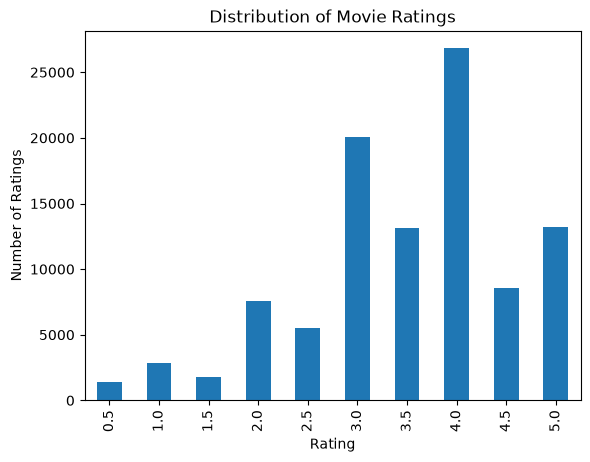

In [75]:
### Rating Distribution

import matplotlib.pyplot as plt

ratings["rating"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

Observation: Ratings tend to be concentrated toward the higher end of the rating scale, with 4.0 being the most frequently assigned rating.

In [76]:
### Most Common Genres

genres_exploded = movies.explode("genre_list")

In [79]:
genres_exploded.head(10)

,movieId,title,genres,genre_list
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Adventure
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Animation
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Children
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Comedy
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy,Adventure
1,2,Jumanji (1995),Adventure|Children|Fantasy,Children
1,2,Jumanji (1995),Adventure|Children|Fantasy,Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance,Comedy
2,3,Grumpier Old Men (1995),Comedy|Romance,Romance


In [77]:
genre_counts = genres_exploded["genre_list"].value_counts()

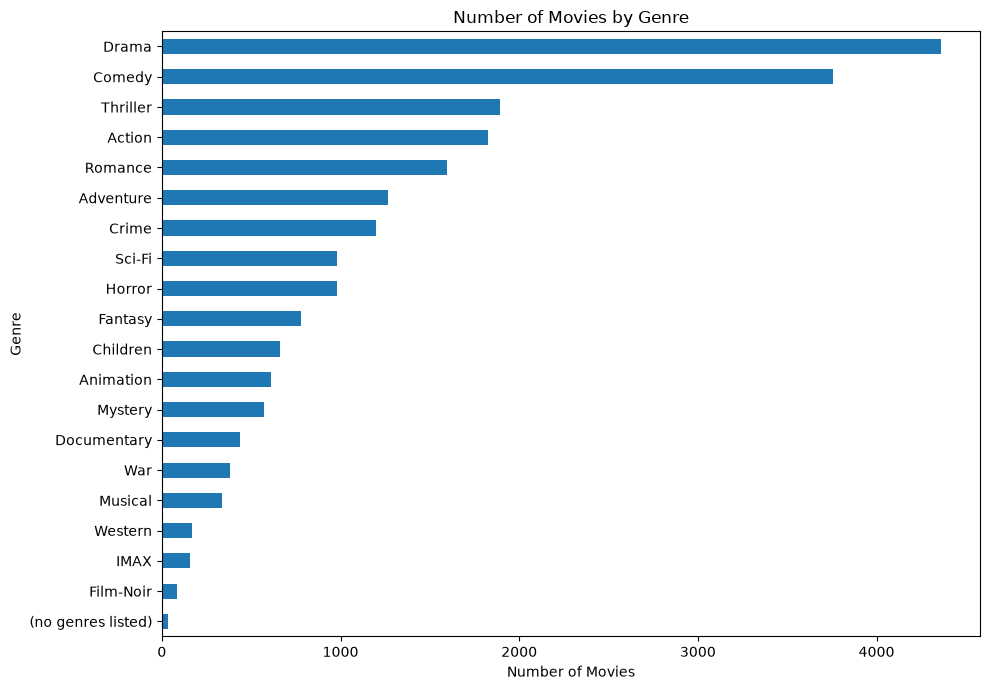

In [81]:
plt.figure(figsize=(10, 7))

genre_counts.sort_values().plot(kind="barh")

plt.title("Number of Movies by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

Drama, Comedy, Thriller are top the top 3 genres

In [100]:
### Most rated movies

most_rated = (
    movies_ratings
    .groupby(["movieId", "title"])
    ["rating"]
    .count()
    .sort_values(ascending=False)
    .head(10)
)

most_rated

movieId  title                                    
356      Forrest Gump (1994)                          329
318      Shawshank Redemption, The (1994)             317
296      Pulp Fiction (1994)                          307
593      Silence of the Lambs, The (1991)             279
2571     Matrix, The (1999)                           278
260      Star Wars: Episode IV - A New Hope (1977)    251
480      Jurassic Park (1993)                         238
110      Braveheart (1995)                            237
589      Terminator 2: Judgment Day (1991)            224
527      Schindler's List (1993)                      220
Name: rating, dtype: int64

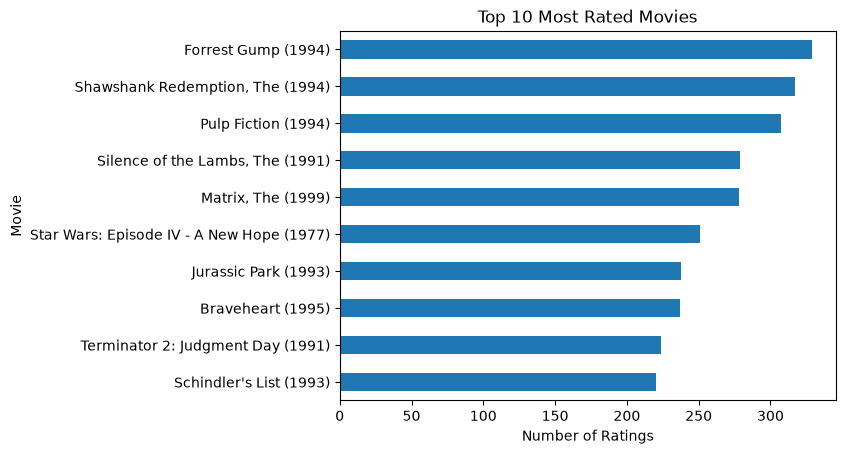

In [95]:
most_rated.sort_values().plot(kind="barh")

plt.title("Top 10 Most Rated Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie")
plt.show()

In [97]:
### Average rating of movie vs popularity
movie_stats = (
    movies_ratings
    .groupby(["movieId", "title"])
    ["rating"]
    .agg(["mean", "count"])
    .reset_index()
)

movie_stats.head()

,movieId,title,mean,count
0,1,Toy Story (1995),3.920930,215
1,2,Jumanji (1995),3.431818,110
2,3,Grumpier Old Men (1995),3.259615,52
3,4,Waiting to Exhale (1995),2.357143,7
4,5,Father of the Bride Part II (1995),3.071429,49


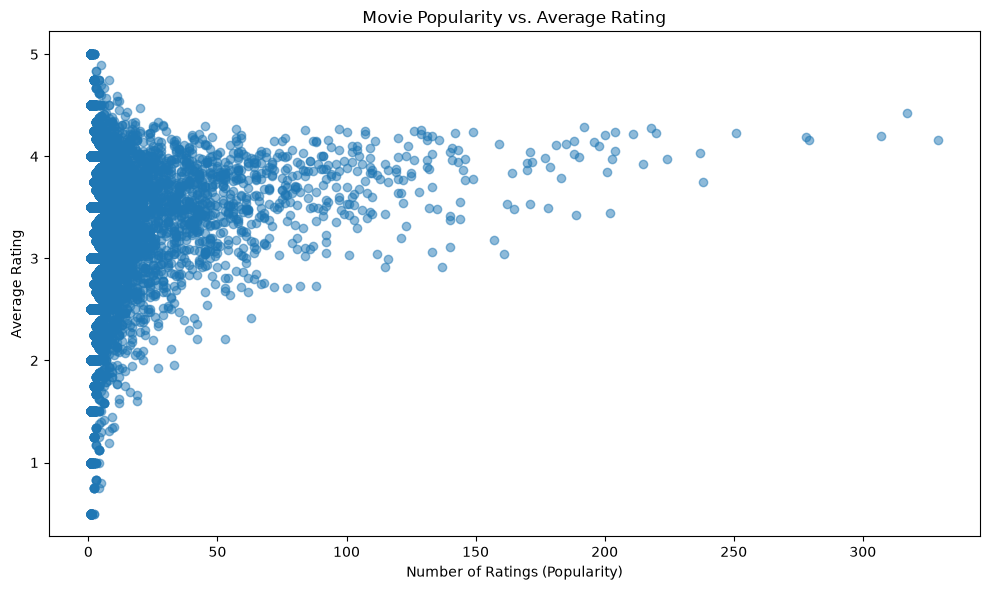

In [99]:
plt.figure(figsize=(10, 6))

plt.scatter(
    movie_stats["count"],
    movie_stats["mean"],
    alpha=0.5
)

plt.title("Movie Popularity vs. Average Rating")
plt.xlabel("Number of Ratings (Popularity)")
plt.ylabel("Average Rating")

plt.tight_layout()
plt.show()

There is a trend of movies with a higher number of ratings having higher average scores. This is especially noticeable after approximately 200 ratings, where the average ratings are all above 3. However, movies with a low number of ratings can also have very high average scores, which may not accurately represent whether the movie is generally well received. A larger number of ratings provides a more reliable representation of the overall audience opinion.

In [103]:
movies_processed = movies.drop(columns=["genre_list"]).copy()

In [104]:
movies_processed.to_csv(
    "../data/processed/movies_processed.csv",
    index=False
)